In [ ]:
from google.colab import drive
import os
drive.mount('/content/drive')

project_dir = '/content/drive/MyDrive/Mu_Receptor_Project'
os.makedirs(project_dir, exist_ok=True)
os.chdir(project_dir)
print("Working in:", os.getcwd())

Mounted at /content/drive
Working in: /content/drive/MyDrive/Mu_Receptor_Project


In [ ]:
!pip install -q condacolab
import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to
condacolab==0.1 as a workaround.

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:10
🔁 Restarting kernel...


In [ ]:
!mamba install -c conda-forge -y openmm pdbfixer biopython openff-toolkit-base openmmforcefields ambertools rdkit

[+] 0.0s
[+] 0.0s
[+] 0.1s
conda-forge/linux-64   1%
conda-forge/noarch    ⣾  [+] 0.2s
conda-forge/linux-64  10%
conda-forge/noarch     7%[+] 0.3s
conda-forge/linux-64  16%
conda-forge/noarch    20%[+] 0.4s
conda-forge/linux-64  21%
conda-forge/noarch    30%[+] 0.5s
conda-forge/linux-64  23%
conda-forge/noarch    35%[+] 0.6s
conda-forge/linux-64  27%
conda-forge/noarch    41%[+] 0.7s
conda-forge/linux-64  29%
conda-forge/noarch    46%[+] 0.8s
conda-forge/linux-64  35%
conda-forge/noarch    57%[+] 0.9s
conda-forge/linux-64  35%
conda-forge/noarch    59%[+] 1.0s
conda-forge/linux-64  35%
conda-forge/noarch    59%[+] 1.1s
conda-forge/linux-64  35%
conda-forge/noarch    59%[+] 1.2s
conda-forge/linux-64  35%
conda-forge/noarch    59%[+] 1.3s
conda-forge/linux-64  35%
conda-forge/noarch    59%[+] 1.4s
conda-forge/linux-64  35%
conda-forge/noarch    59%[+] 1.5s
conda-forge/linux-64  35%
conda-forge/noarch    59%[+] 1.6s
conda-forge/linux-64  35%
conda-forge/noarch    59%[+] 1.7s
conda-forge/l

In [ ]:
import sys
!{sys.executable} -m pip uninstall -y torchvision torchaudio torchcodec torchao torchtune

Found existing installation: torchvision 0.26.0+cu130
Uninstalling torchvision-0.26.0+cu130:
  Successfully uninstalled torchvision-0.26.0+cu130
Found existing installation: torchaudio 2.11.0+cu130
Uninstalling torchaudio-2.11.0+cu130:
  Successfully uninstalled torchaudio-2.11.0+cu130
Found existing installation: torchcodec 0.11.0+cu130
Uninstalling torchcodec-0.11.0+cu130:
  Successfully uninstalled torchcodec-0.11.0+cu130
Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
Found existing installation: torchtune 0.6.1
Uninstalling torchtune-0.6.1:
  Successfully uninstalled torchtune-0.6.1


In [ ]:
from openff.toolkit import Molecule
import openmm
print("OK", openmm.__version__)
from openmm import Platform
print([Platform.getPlatform(i).getName() for i in range(Platform.getNumPlatforms())])

In [ ]:
import os
from google.colab import drive, files
drive.mount('/content/drive')
os.chdir('/content/drive/MyDrive/Mu_Receptor_Project')

if not os.path.exists('8EF5.pdb'):
    print("Download the PDB file from rcsb.org/structure/8EF5 and upload it")
    up = files.upload()
    os.replace(list(up.keys())[0], '8EF5.pdb')
print("8EF5.pdb exists:", os.path.exists('8EF5.pdb'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
8EF5.pdb exists: True


In [ ]:
import os, urllib.request
import numpy as np
from google.colab import drive
drive.mount('/content/drive')

project_dir = '/content/drive/MyDrive/Mu_Receptor_Project'
os.chdir(project_dir)
print("Working in:", os.getcwd())

from openmm.app import *
from openmm import *
from openmm.unit import *
from openmmforcefields.generators import GAFFTemplateGenerator
from openff.toolkit import Molecule
from openff.units.openmm import to_openmm
from pdbfixer import PDBFixer
from rdkit import Chem
from rdkit.Chem import AllChem

VARIANTS = {'wt': None, 'r181c': 'ARG-181-CYS'}   # prefix: mutation
RECEPTOR_CHAIN = 'R'
LIGAND = '7V7'

def xyz_of(l):
    return np.array([float(l[30:38]), float(l[38:46]), float(l[46:54])])

# ---------- 1. OPM oriented file ----------
opm_file = 'opm_8ef5.pdb'
if not os.path.exists(opm_file):
    urls = ['https://opm-assets.storage.googleapis.com/pdb/8ef5.pdb',
            'https://opm-assets.storage.googleapis.com/pdb/8EF5.pdb']
    ok = False
    for u in urls:
        try:
            urllib.request.urlretrieve(u, opm_file)
            if os.path.getsize(opm_file) > 10000:
                ok = True
                print("OPM file downloaded:", u)
                break
        except Exception as e:
            print("Download failed:", u, str(e)[:60])
    if not ok:
        print("Automatic download failed. Search for 8ef5 on opm.phar.umich.edu, download the PDB and upload it here.")
        from google.colab import files
        up = files.upload()
        os.replace(list(up.keys())[0], opm_file)

# ---------- 2. Receptor + ligand from the original 8EF5 (only ONE copy) ----------
raw = open('8EF5.pdb').read().splitlines()
rec = [l[:16] + ' ' + l[17:] for l in raw
       if l.startswith('ATOM') and l[21] == RECEPTOR_CHAIN and l[16] in ' A']
assert rec, "Receptor chain R not found in 8EF5.pdb"
rec_xyz = np.array([xyz_of(l) for l in rec])

lig_groups = {}
for l in raw:
    if l.startswith('HETATM') and l[17:20].strip() == LIGAND and l[16] in ' A':
        lig_groups.setdefault((l[21], l[22:27]), []).append(l[:16] + ' ' + l[17:])
assert lig_groups, "Ligand 7V7 not found in 8EF5.pdb"

print("\n--- Ligand copies in 8EF5.pdb ---")
best_key, best_n = None, -1
for k, g in lig_groups.items():
    gx = np.array([xyz_of(l) for l in g])
    d = np.linalg.norm(gx[:, None, :] - rec_xyz[None, :, :], axis=2)
    n_contact = int((d.min(axis=1) < 4.5).sum())
    print(f"chain {k[0]} | resnum {k[1].strip()} | atoms: {len(g)} | atoms within 4.5 A of receptor: {n_contact}")
    if n_contact > best_n:
        best_key, best_n = k, n_contact
lig = lig_groups[best_key]
print(f"==> Selected copy: chain {best_key[0]} resnum {best_key[1].strip()} | heavy atoms: {len(lig)}")
assert len(lig) == 25, f"Fentanyl should have 25 heavy atoms, found {len(lig)}"
print("Receptor atoms:", len(rec))

# ---------- 3. CA superposition: 8EF5 -> OPM ----------
def ca_dict(lines, chain=None):
    d = {}
    for l in lines:
        if l.startswith('ATOM') and l[12:16].strip() == 'CA' and l[16] in ' A':
            if chain is None or l[21] == chain:
                d[l[22:27].strip()] = xyz_of(l)
    return d

p_ca = ca_dict(rec)
opm_lines = open(opm_file).read().splitlines()
q_ca = ca_dict(opm_lines, RECEPTOR_CHAIN)
if len(set(p_ca) & set(q_ca)) < 100:
    q_ca = ca_dict(opm_lines)
common = sorted(set(p_ca) & set(q_ca))
print("Common CA atoms:", len(common))
assert len(common) >= 100, "Residues did not match the OPM file"

P = np.array([p_ca[k] for k in common]); Q = np.array([q_ca[k] for k in common])
Pc, Qc = P.mean(0), Q.mean(0)
H = (P - Pc).T @ (Q - Qc)
U, S, Vt = np.linalg.svd(H)
dsign = np.sign(np.linalg.det(Vt.T @ U.T))
R = Vt.T @ np.diag([1, 1, dsign]) @ U.T
rmsd = np.sqrt((((P - Pc) @ R.T + Qc - Q) ** 2).sum(1).mean())
print(f"Superposition RMSD: {rmsd:.2f} A")

def transform(lines):
    out = []
    for l in lines:
        x = (xyz_of(l) - Pc) @ R.T + Qc
        out.append(l[:30] + f"{x[0]:8.3f}{x[1]:8.3f}{x[2]:8.3f}" + l[54:])
    return out

rec_o, lig_o = transform(rec), transform(lig)
open('oriented_receptor_raw.pdb', 'w').write('\n'.join(rec_o) + '\nEND\n')
open('lig_heavy_oriented.pdb', 'w').write('\n'.join(lig_o) + '\nEND\n')

ca = np.array([xyz_of(l) for l in rec_o if l[12:16].strip() == 'CA'])
print(f"CA z range after orientation: {ca[:,2].min()/10:.1f} to {ca[:,2].max()/10:.1f} nm")

# ---------- 4. Fentanyl (built once) ----------
template = Chem.MolFromSmiles('CCC(=O)N(c1ccccc1)C1CCN(CC1)CCc1ccccc1')
lig_mol = Chem.MolFromPDBFile('lig_heavy_oriented.pdb', removeHs=True)
lig_mol = AllChem.AssignBondOrdersFromTemplate(template, lig_mol)
n_idx = lig_mol.GetSubstructMatch(Chem.MolFromSmarts('[NX3;!$(N-C=O);!$(N-c)]'))[0]
lig_mol.GetAtomWithIdx(n_idx).SetFormalCharge(1)
Chem.SanitizeMol(lig_mol)
lig_mol = Chem.AddHs(lig_mol, addCoords=True)
assert len(Chem.GetMolFrags(lig_mol)) == 1, "Ligand is split into more than one fragment"
Chem.MolToMolFile(lig_mol, 'fentanyl_oriented.sdf')
fentanyl = Molecule.from_rdkit(lig_mol, allow_undefined_stereo=True)
print("Fentanyl atoms (with H):", fentanyl.n_atoms, "| formal charge:", fentanyl.total_charge)
gaff = GAFFTemplateGenerator(molecules=[fentanyl], forcefield='gaff-2.11')

# ---------- 5. Build a system for each variant ----------
def build(prefix, mutation):
    print(f"\n================ {prefix.upper()} ({mutation or 'wild-type'}) ================")
    fixer = PDBFixer(filename='oriented_receptor_raw.pdb')
    fixer.findMissingResidues()
    fixer.missingResidues = {}
    if mutation:
        fixer.applyMutations([mutation], RECEPTOR_CHAIN)
    fixer.findMissingAtoms()
    fixer.addMissingAtoms()
    with open(f'{prefix}_protein.pdb', 'w') as f:
        PDBFile.writeFile(fixer.topology, fixer.positions, f)

    ff = ForceField('amber14-all.xml', 'amber14/tip3p.xml')
    ff.registerTemplateGenerator(gaff.generator)

    pdb = PDBFile(f'{prefix}_protein.pdb')
    modeller = Modeller(pdb.topology, pdb.positions)
    modeller.addHydrogens(ff, pH=7.0)
    modeller.add(fentanyl.to_topology().to_openmm(), to_openmm(fentanyl.conformers[0]))
    with open(f'{prefix}_complex_with_H.pdb', 'w') as f:
        PDBFile.writeFile(modeller.topology, modeller.positions, f)

    print("Adding membrane (takes a few minutes)...")
    modeller.addMembrane(ff, lipidType='POPC',
                         membraneCenterZ=0*nanometer,
                         minimumPadding=1.0*nanometer,
                         ionicStrength=0.15*molar, neutralize=True)
    with open(f'{prefix}_system_solvated.pdb', 'w') as f:
        PDBFile.writeFile(modeller.topology, modeller.positions, f)
    n_popc = len([r for r in modeller.topology.residues() if r.name == 'POP'])
    print(f"Saved: {prefix}_system_solvated.pdb | atoms: {modeller.topology.getNumAtoms()} | POPC lipids: {n_popc}")

    system = ff.createSystem(modeller.topology, nonbondedMethod=PME,
                             nonbondedCutoff=1.0*nanometer, constraints=HBonds)
    system.addForce(MonteCarloMembraneBarostat(
        1*bar, 0*bar*nanometer, 300*kelvin,
        MonteCarloMembraneBarostat.XYIsotropic,
        MonteCarloMembraneBarostat.ZFree, 100))
    with open(f'{prefix}_system.xml', 'w') as f:
        f.write(XmlSerializer.serialize(system))

    sim = None
    for name in ['OpenCL', 'CPU']:
        try:
            integ = LangevinMiddleIntegrator(300*kelvin, 1/picosecond, 0.002*picoseconds)
            sim = Simulation(modeller.topology, system, integ, Platform.getPlatformByName(name))
            print("Platform:", name)
            break
        except Exception as e:
            print(name, "failed:", str(e)[:80])
    assert sim is not None, "No platform could be started"
    sim.context.setPositions(modeller.positions)
    print("Energy before:", sim.context.getState(getEnergy=True).getPotentialEnergy())
    sim.minimizeEnergy(maxIterations=5000)
    st = sim.context.getState(getPositions=True, getEnergy=True)
    print("Energy after:", st.getPotentialEnergy())
    with open(f'{prefix}_minimized.pdb', 'w') as f:
        PDBFile.writeFile(sim.topology, st.getPositions(), f)
    sim.saveState(f'{prefix}_minimized_state.xml')
    print(f"Saved: {prefix}_system.xml, {prefix}_minimized.pdb, {prefix}_minimized_state.xml")

for prefix, mut in VARIANTS.items():
    build(prefix, mut)

print("\nFiles in Drive:", sorted(os.listdir('.')))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in: /content/drive/MyDrive/Mu_Receptor_Project

--- Ligand copies in 8EF5.pdb ---
chain R | resnum 501 | atoms: 25 | atoms within 4.5 A of receptor: 23
chain M | resnum 501 | atoms: 25 | atoms within 4.5 A of receptor: 0
==> Selected copy: chain R resnum 501 | heavy atoms: 25
Receptor atoms: 2309
Common CA atoms: 287
Superposition RMSD: 0.00 A
CA z range after orientation: -3.3 to 2.8 nm
Fentanyl atoms (with H): 54 | formal charge: 1.0 elementary_charge

================ WT (wild-type) ================


[14:13:01] WARNING: More than one matching pattern found - picking one



Adding membrane (takes a few minutes)...
Saved: wt_system_solvated.pdb | atoms: 145939 | POPC lipids: 480
OpenCL failed: There is no registered Platform called "OpenCL"
Platform: CPU
Energy before: -1536402.0433376005 kJ/mol
Energy after: -1956140.4523958948 kJ/mol
Saved: wt_system.xml, wt_minimized.pdb, wt_minimized_state.xml

================ R181C (ARG-181-CYS) ================
Adding membrane (takes a few minutes)...
Saved: r181c_system_solvated.pdb | atoms: 145871 | POPC lipids: 480
OpenCL failed: There is no registered Platform called "OpenCL"
Platform: CPU
Energy before: -1505232.2517047427 kJ/mol
Energy after: -1956860.8309096938 kJ/mol
Saved: r181c_system.xml, r181c_minimized.pdb, r181c_minimized_state.xml

Files in Drive: ['.ipynb_checkpoints', '8EF5.pdb', 'fentanyl_oriented.sdf', 'lig_heavy_oriented.pdb', 'opm_8ef5.pdb', 'oriented_receptor_raw.pdb', 'r181c_complex_with_H.pdb', 'r181c_minimized.pdb', 'r181c_minimized_state.xml', 'r181c_protein.pdb', 'r181c_system.xml', 'r181c

In [ ]:
import os, urllib.request
import numpy as np
from google.colab import drive
drive.mount('/content/drive')

project_dir = '/content/drive/MyDrive/Mu_Receptor_Project'
os.chdir(project_dir)
print("Working in:", os.getcwd())

from openmm.app import *
from openmm import *
from openmm.unit import *
from openmmforcefields.generators import GAFFTemplateGenerator
from openff.toolkit import Molecule
from openff.units.openmm import to_openmm
from pdbfixer import PDBFixer
from rdkit import Chem
from rdkit.Chem import AllChem

VARIANTS = {'wt': None, 'r181c': 'ARG-181-CYS'}   # prefix: mutation
RECEPTOR_CHAIN = 'R'
LIGAND = '7V7'

def xyz_of(l):
    return np.array([float(l[30:38]), float(l[38:46]), float(l[46:54])])

# ---------- 1. OPM oriented file ----------
opm_file = 'opm_8ef5.pdb'
if not os.path.exists(opm_file):
    urls = ['https://opm-assets.storage.googleapis.com/pdb/8ef5.pdb',
            'https://opm-assets.storage.googleapis.com/pdb/8EF5.pdb']
    ok = False
    for u in urls:
        try:
            urllib.request.urlretrieve(u, opm_file)
            if os.path.getsize(opm_file) > 10000:
                ok = True
                print("OPM file downloaded:", u)
                break
        except Exception as e:
            print("Download failed:", u, str(e)[:60])
    if not ok:
        print("Automatic download failed. Search for 8ef5 on opm.phar.umich.edu, download the PDB and upload it here.")
        from google.colab import files
        up = files.upload()
        os.replace(list(up.keys())[0], opm_file)

# ---------- 2. Receptor + ligand from the original 8EF5 (only ONE copy) ----------
raw = open('8EF5.pdb').read().splitlines()
rec = [l[:16] + ' ' + l[17:] for l in raw
       if l.startswith('ATOM') and l[21] == RECEPTOR_CHAIN and l[16] in ' A']
assert rec, "Receptor chain R not found in 8EF5.pdb"
rec_xyz = np.array([xyz_of(l) for l in rec])

lig_groups = {}
for l in raw:
    if l.startswith('HETATM') and l[17:20].strip() == LIGAND and l[16] in ' A':
        lig_groups.setdefault((l[21], l[22:27]), []).append(l[:16] + ' ' + l[17:])
assert lig_groups, "Ligand 7V7 not found in 8EF5.pdb"

print("\n--- Ligand copies in 8EF5.pdb ---")
best_key, best_n = None, -1
for k, g in lig_groups.items():
    gx = np.array([xyz_of(l) for l in g])
    d = np.linalg.norm(gx[:, None, :] - rec_xyz[None, :, :], axis=2)
    n_contact = int((d.min(axis=1) < 4.5).sum())
    print(f"chain {k[0]} | resnum {k[1].strip()} | atoms: {len(g)} | atoms within 4.5 A of receptor: {n_contact}")
    if n_contact > best_n:
        best_key, best_n = k, n_contact
lig = lig_groups[best_key]
print(f"==> Selected copy: chain {best_key[0]} resnum {best_key[1].strip()} | heavy atoms: {len(lig)}")
assert len(lig) == 25, f"Fentanyl should have 25 heavy atoms, found {len(lig)}"
print("Receptor atoms:", len(rec))

# ---------- 3. CA superposition: 8EF5 -> OPM ----------
def ca_dict(lines, chain=None):
    d = {}
    for l in lines:
        if l.startswith('ATOM') and l[12:16].strip() == 'CA' and l[16] in ' A':
            if chain is None or l[21] == chain:
                d[l[22:27].strip()] = xyz_of(l)
    return d

p_ca = ca_dict(rec)
opm_lines = open(opm_file).read().splitlines()
q_ca = ca_dict(opm_lines, RECEPTOR_CHAIN)
if len(set(p_ca) & set(q_ca)) < 100:
    q_ca = ca_dict(opm_lines)
common = sorted(set(p_ca) & set(q_ca))
print("Common CA atoms:", len(common))
assert len(common) >= 100, "Residues did not match the OPM file"

P = np.array([p_ca[k] for k in common]); Q = np.array([q_ca[k] for k in common])
Pc, Qc = P.mean(0), Q.mean(0)
H = (P - Pc).T @ (Q - Qc)
U, S, Vt = np.linalg.svd(H)
dsign = np.sign(np.linalg.det(Vt.T @ U.T))
R = Vt.T @ np.diag([1, 1, dsign]) @ U.T
rmsd = np.sqrt((((P - Pc) @ R.T + Qc - Q) ** 2).sum(1).mean())
print(f"Superposition RMSD: {rmsd:.2f} A")

def transform(lines):
    out = []
    for l in lines:
        x = (xyz_of(l) - Pc) @ R.T + Qc
        out.append(l[:30] + f"{x[0]:8.3f}{x[1]:8.3f}{x[2]:8.3f}" + l[54:])
    return out

rec_o, lig_o = transform(rec), transform(lig)
open('oriented_receptor_raw.pdb', 'w').write('\n'.join(rec_o) + '\nEND\n')
open('lig_heavy_oriented.pdb', 'w').write('\n'.join(lig_o) + '\nEND\n')

ca = np.array([xyz_of(l) for l in rec_o if l[12:16].strip() == 'CA'])
print(f"CA z range after orientation: {ca[:,2].min()/10:.1f} to {ca[:,2].max()/10:.1f} nm")

# ---------- 4. Fentanyl (built once) ----------
template = Chem.MolFromSmiles('CCC(=O)N(c1ccccc1)C1CCN(CC1)CCc1ccccc1')
lig_mol = Chem.MolFromPDBFile('lig_heavy_oriented.pdb', removeHs=True)
lig_mol = AllChem.AssignBondOrdersFromTemplate(template, lig_mol)
n_idx = lig_mol.GetSubstructMatch(Chem.MolFromSmarts('[NX3;!$(N-C=O);!$(N-c)]'))[0]
lig_mol.GetAtomWithIdx(n_idx).SetFormalCharge(1)
Chem.SanitizeMol(lig_mol)
lig_mol = Chem.AddHs(lig_mol, addCoords=True)
assert len(Chem.GetMolFrags(lig_mol)) == 1, "Ligand is split into more than one fragment"
Chem.MolToMolFile(lig_mol, 'fentanyl_oriented.sdf')
fentanyl = Molecule.from_rdkit(lig_mol, allow_undefined_stereo=True)
print("Fentanyl atoms (with H):", fentanyl.n_atoms, "| formal charge:", fentanyl.total_charge)
gaff = GAFFTemplateGenerator(molecules=[fentanyl], forcefield='gaff-2.11')

# ---------- 5. Build a system for each variant ----------
def build(prefix, mutation):
    print(f"\n================ {prefix.upper()} ({mutation or 'wild-type'}) ================")
    fixer = PDBFixer(filename='oriented_receptor_raw.pdb')
    fixer.findMissingResidues()
    fixer.missingResidues = {}
    if mutation:
        fixer.applyMutations([mutation], RECEPTOR_CHAIN)
    fixer.findMissingAtoms()
    fixer.addMissingAtoms()
    with open(f'{prefix}_protein.pdb', 'w') as f:
        PDBFile.writeFile(fixer.topology, fixer.positions, f)

    ff = ForceField('amber14-all.xml', 'amber14/tip3p.xml')
    ff.registerTemplateGenerator(gaff.generator)

    pdb = PDBFile(f'{prefix}_protein.pdb')
    modeller = Modeller(pdb.topology, pdb.positions)
    modeller.addHydrogens(ff, pH=7.0)
    modeller.add(fentanyl.to_topology().to_openmm(), to_openmm(fentanyl.conformers[0]))
    with open(f'{prefix}_complex_with_H.pdb', 'w') as f:
        PDBFile.writeFile(modeller.topology, modeller.positions, f)

    print("Adding membrane (takes a few minutes)...")
    modeller.addMembrane(ff, lipidType='POPC',
                         membraneCenterZ=0*nanometer,
                         minimumPadding=1.0*nanometer,
                         ionicStrength=0.15*molar, neutralize=True)
    with open(f'{prefix}_system_solvated.pdb', 'w') as f:
        PDBFile.writeFile(modeller.topology, modeller.positions, f)
    n_popc = len([r for r in modeller.topology.residues() if r.name == 'POP'])
    print(f"Saved: {prefix}_system_solvated.pdb | atoms: {modeller.topology.getNumAtoms()} | POPC lipids: {n_popc}")

    system = ff.createSystem(modeller.topology, nonbondedMethod=PME,
                             nonbondedCutoff=1.0*nanometer, constraints=HBonds)
    system.addForce(MonteCarloMembraneBarostat(
        1*bar, 0*bar*nanometer, 300*kelvin,
        MonteCarloMembraneBarostat.XYIsotropic,
        MonteCarloMembraneBarostat.ZFree, 100))
    with open(f'{prefix}_system.xml', 'w') as f:
        f.write(XmlSerializer.serialize(system))

    sim = None
    for name in ['OpenCL', 'CPU']:
        try:
            integ = LangevinMiddleIntegrator(300*kelvin, 1/picosecond, 0.002*picoseconds)
            sim = Simulation(modeller.topology, system, integ, Platform.getPlatformByName(name))
            print("Platform:", name)
            break
        except Exception as e:
            print(name, "failed:", str(e)[:80])
    assert sim is not None, "No platform could be started"
    sim.context.setPositions(modeller.positions)
    print("Energy before:", sim.context.getState(getEnergy=True).getPotentialEnergy())
    sim.minimizeEnergy(maxIterations=5000)
    st = sim.context.getState(getPositions=True, getEnergy=True)
    print("Energy after:", st.getPotentialEnergy())
    with open(f'{prefix}_minimized.pdb', 'w') as f:
        PDBFile.writeFile(sim.topology, st.getPositions(), f)
    sim.saveState(f'{prefix}_minimized_state.xml')
    print(f"Saved: {prefix}_system.xml, {prefix}_minimized.pdb, {prefix}_minimized_state.xml")

for prefix, mut in VARIANTS.items():
    build(prefix, mut)

print("\nFiles in Drive:", sorted(os.listdir('.')))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in: /content/drive/MyDrive/Mu_Receptor_Project

--- Ligand copies in 8EF5.pdb ---
chain R | resnum 501 | atoms: 25 | atoms within 4.5 A of receptor: 23
chain M | resnum 501 | atoms: 25 | atoms within 4.5 A of receptor: 0
==> Selected copy: chain R resnum 501 | heavy atoms: 25
Receptor atoms: 2309
Common CA atoms: 287
Superposition RMSD: 0.00 A
CA z range after orientation: -3.3 to 2.8 nm


[17:44:00] WARNING: More than one matching pattern found - picking one



Fentanyl atoms (with H): 54 | formal charge: 1.0 elementary_charge

================ WT (wild-type) ================
Adding membrane (takes a few minutes)...
Saved: wt_system_solvated.pdb | atoms: 145610 | POPC lipids: 480
OpenCL failed: There is no registered Platform called "OpenCL"
Platform: CPU
Energy before: -1515124.5320949834 kJ/mol
Energy after: -1951608.7662981015 kJ/mol
Saved: wt_system.xml, wt_minimized.pdb, wt_minimized_state.xml

================ R181C (ARG-181-CYS) ================
Adding membrane (takes a few minutes)...
Saved: r181c_system_solvated.pdb | atoms: 145865 | POPC lipids: 480
OpenCL failed: There is no registered Platform called "OpenCL"
Platform: CPU
Energy before: -1529927.7640023779 kJ/mol
Energy after: -1944676.21213635 kJ/mol
Saved: r181c_system.xml, r181c_minimized.pdb, r181c_minimized_state.xml

Files in Drive: ['.ipynb_checkpoints', '8EF5.pdb', 'fentanyl_oriented.sdf', 'lig_heavy_oriented.pdb', 'opm_8ef5.pdb', 'oriented_receptor_raw.pdb', 'r181c_compl

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')

os.chdir('/content/drive/MyDrive/Mu_Receptor_Project')
print("Working in:", os.getcwd())

from openmm.app import *
from openmm import *
from openmm.unit import *

VARIANTS = ['wt', 'r181c']
NOT_RESTRAINED = {'HOH', 'WAT', 'NA', 'CL', 'POP', 'POPC', 'PA', 'PC', 'OL'}

# (name, restraint k [kJ/mol/nm^2], steps (2 fs), barostat on?)
STAGES = [
    ('nvt_k1000', 1000.0,  50000, False),   # 100 ps
    ('npt_k1000', 1000.0, 125000, True),    # 250 ps
    ('npt_k500',   500.0, 125000, True),    # 250 ps
    ('npt_k100',   100.0, 125000, True),    # 250 ps
    ('npt_k10',     10.0, 125000, True),    # 250 ps
]

def pick_platform(system, topology):
    for name in ['OpenCL', 'CPU']:
        try:
            integ = LangevinMiddleIntegrator(300*kelvin, 1/picosecond, 0.002*picoseconds)
            sim = Simulation(topology, system, integ, Platform.getPlatformByName(name))
            print("Platform:", name)
            return sim
        except Exception as e:
            print(name, "failed:", str(e)[:80])
    raise RuntimeError("No platform worked")

def equilibrate(prefix):
    final_state = f'{prefix}_equilibrated_state.xml'
    if os.path.exists(final_state):
        print(f"\n{prefix}: equilibration already done ({final_state}), skipping.")
        return
    print(f"\n================ {prefix.upper()} equilibration ================")

    pdb = PDBFile(f'{prefix}_system_solvated.pdb')
    with open(f'{prefix}_system.xml') as f:
        system = XmlSerializer.deserialize(f.read())

    # Remove any existing barostat and add a membrane barostat (initially off)
    for i in reversed(range(system.getNumForces())):
        if isinstance(system.getForce(i), (MonteCarloMembraneBarostat, MonteCarloBarostat)):
            system.removeForce(i)
    barostat = MonteCarloMembraneBarostat(1*bar, 0*bar*nanometer, 300*kelvin,
                                          MonteCarloMembraneBarostat.XYIsotropic,
                                          MonteCarloMembraneBarostat.ZFree, 0)
    system.addForce(barostat)

    with open(f'{prefix}_minimized_state.xml') as f:
        min_state = XmlSerializer.deserialize(f.read())
    min_pos = min_state.getPositions()

    # Positional restraints on heavy atoms of protein + ligand
    restraint = CustomExternalForce('k*periodicdistance(x, y, z, x0, y0, z0)^2')
    restraint.addGlobalParameter('k', 1000.0)
    restraint.addPerParticleParameter('x0')
    restraint.addPerParticleParameter('y0')
    restraint.addPerParticleParameter('z0')
    n_res = 0
    for atom in pdb.topology.atoms():
        if atom.residue.name in NOT_RESTRAINED:
            continue
        if atom.element is not None and atom.element.symbol != 'H':
            p = min_pos[atom.index].value_in_unit(nanometer)
            restraint.addParticle(atom.index, [p[0], p[1], p[2]])
            n_res += 1
    system.addForce(restraint)
    print("Restrained heavy atoms (protein + ligand):", n_res)

    sim = pick_platform(system, pdb.topology)
    sim.context.setState(min_state)
    sim.context.setVelocitiesToTemperature(300*kelvin)

    sim.reporters.append(StateDataReporter(f'{prefix}_equil.log', 5000, step=True,
                         potentialEnergy=True, temperature=True, volume=True,
                         speed=True, append=True))

    for name, k, nsteps, baro_on in STAGES:
        stage_file = f'{prefix}_{name}_state.xml'
        if os.path.exists(stage_file):
            sim.loadState(stage_file)
            print(f"{name}: already exists, loaded.")
            continue
        barostat.setFrequency(100 if baro_on else 0)
        sim.context.reinitialize(preserveState=True)
        sim.context.setParameter('k', k)
        print(f"{name}: k={k:.0f}, {nsteps*0.002:.0f} ps, barostat={'on' if baro_on else 'off'}")
        sim.step(nsteps)
        st = sim.context.getState(getEnergy=True)
        print(f"   finished | energy: {st.getPotentialEnergy()}")
        sim.saveState(stage_file)

    state = sim.context.getState(getPositions=True, getVelocities=True, enforcePeriodicBox=True)
    with open(f'{prefix}_equilibrated.pdb', 'w') as f:
        PDBFile.writeFile(sim.topology, state.getPositions(), f)
    sim.saveState(final_state)
    bv = state.getPeriodicBoxVectors()
    print(f"Final box (nm): x={bv[0][0].value_in_unit(nanometer):.2f}, "
          f"y={bv[1][1].value_in_unit(nanometer):.2f}, z={bv[2][2].value_in_unit(nanometer):.2f}")
    print(f"Saved: {prefix}_equilibrated.pdb, {final_state}")

for v in VARIANTS:
    equilibrate(v)

print("\nFiles in Drive:", sorted(f for f in os.listdir('.') if 'equil' in f or '_state' in f))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in: /content/drive/MyDrive/Mu_Receptor_Project

================ WT equilibration ================
Restrained heavy atoms (protein + ligand): 2335
Platform: OpenCL
nvt_k1000: k=1000, 100 ps, barostat=off
   finished | energy: -1513662.5218212148 kJ/mol
npt_k1000: k=1000, 250 ps, barostat=on
   finished | energy: -1537167.0998971732 kJ/mol
npt_k500: k=500, 250 ps, barostat=on
   finished | energy: -1537267.3174811024 kJ/mol
npt_k100: k=100, 250 ps, barostat=on
   finished | energy: -1538732.7396552935 kJ/mol
npt_k10: k=10, 250 ps, barostat=on
   finished | energy: -1539075.5770248724 kJ/mol
Final box (nm): x=12.29, y=12.91, z=8.78
Saved: wt_equilibrated.pdb, wt_equilibrated_state.xml

================ R181C equilibration ================
Restrained heavy atoms (protein + ligand): 2330
Platform: OpenCL
nvt_k1000: k=1000, 100 ps, barostat=off
   finished

In [ ]:
import os, glob, math
from google.colab import drive
drive.mount('/content/drive')

os.chdir('/content/drive/MyDrive/Mu_Receptor_Project')
print("Working in:", os.getcwd())

from openmm.app import *
from openmm import *
from openmm.unit import *

VARIANTS = ['wt', 'r181c']
N_CHUNKS = 10                   # 10 x 100 ps = 1 ns
STEPS_PER_CHUNK = 50000         # 50000 x 2 fs = 100 ps
REPORT_EVERY = 5000             # one frame every 10 ps

def make_sim(prefix, topology):
    with open(f'{prefix}_system.xml') as f:
        system = XmlSerializer.deserialize(f.read())

    # Remove any existing barostat and add a membrane barostat
    for i in reversed(range(system.getNumForces())):
        if isinstance(system.getForce(i), (MonteCarloMembraneBarostat, MonteCarloBarostat)):
            system.removeForce(i)
    system.addForce(MonteCarloMembraneBarostat(
        1*bar, 0*bar*nanometer, 300*kelvin,
        MonteCarloMembraneBarostat.XYIsotropic,
        MonteCarloMembraneBarostat.ZFree, 100))

    for name in ['OpenCL', 'CPU']:
        try:
            integ = LangevinMiddleIntegrator(300*kelvin, 1/picosecond, 0.002*picoseconds)
            sim = Simulation(topology, system, integ, Platform.getPlatformByName(name))
            print("Platform:", name)
            return sim
        except Exception as e:
            print(name, "failed:", str(e)[:80])
    raise RuntimeError("No platform worked")

def production(prefix):
    final_pdb = f'{prefix}_prod_final.pdb'
    if os.path.exists(final_pdb):
        print(f"\n{prefix}: production already done, skipping.")
        return
    print(f"\n================ {prefix.upper()} production ({N_CHUNKS*100/1000:.0f} ns) ================")

    equil_state = f'{prefix}_equilibrated_state.xml'
    assert os.path.exists(equil_state), f"{equil_state} not found"

    top_pdb = PDBFile(f'{prefix}_system_solvated.pdb')      # used for topology only
    sim = make_sim(prefix, top_pdb.topology)

    prog_file = f'{prefix}_prod_progress.txt'
    done = int(open(prog_file).read()) if os.path.exists(prog_file) else 0

    if done > 0:
        sim.loadState(f'{prefix}_prod_state.xml')
        print(f"Resuming: {done} chunks already completed.")
    else:
        for f in glob.glob(f'{prefix}_prod_*.dcd') + [f'{prefix}_prod.log']:
            if os.path.exists(f):
                os.remove(f)
        with open(equil_state) as f:
            eq = XmlSerializer.deserialize(f.read())
        sim.context.setPeriodicBoxVectors(*eq.getPeriodicBoxVectors())
        sim.context.setPositions(eq.getPositions())
        sim.context.setVelocitiesToTemperature(300*kelvin)
        bv = eq.getPeriodicBoxVectors()
        print("Box (nm): x=%.3f y=%.3f z=%.3f" % (
            bv[0][0].value_in_unit(nanometer),
            bv[1][1].value_in_unit(nanometer),
            bv[2][2].value_in_unit(nanometer)))

    e0 = sim.context.getState(getEnergy=True).getPotentialEnergy().value_in_unit(kilojoule_per_mole)
    print("Starting potential energy: %.0f kJ/mol" % e0)
    assert not math.isnan(e0) and e0 < -1.0e6, "Starting energy is invalid, stopping."

    for i in range(done, N_CHUNKS):
        sim.reporters.clear()
        sim.reporters.append(DCDReporter(f'{prefix}_prod_{i:02d}.dcd', REPORT_EVERY))
        sim.reporters.append(StateDataReporter(f'{prefix}_prod.log', REPORT_EVERY, step=True,
                             potentialEnergy=True, temperature=True, volume=True,
                             speed=True, append=True))
        sim.step(STEPS_PER_CHUNK)
        sim.saveState(f'{prefix}_prod_state.xml')
        open(prog_file, 'w').write(str(i + 1))
        print(f"{prefix}: {(i+1)*100} ps / {N_CHUNKS*100} ps complete, saved")

    st = sim.context.getState(getPositions=True, enforcePeriodicBox=True)
    with open(final_pdb, 'w') as f:
        PDBFile.writeFile(sim.topology, st.getPositions(), f)
    print(f"Saved: {final_pdb}")

for v in VARIANTS:
    production(v)

print("\nFiles:", sorted(f for f in os.listdir('.') if 'prod' in f))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in: /content/drive/MyDrive/Mu_Receptor_Project

================ WT production (1 ns) ================
Platform: OpenCL
Box (nm): x=12.294 y=12.907 z=8.784
Starting potential energy: -1539313 kJ/mol
wt: 100 ps / 1000 ps complete, saved
wt: 200 ps / 1000 ps complete, saved
wt: 300 ps / 1000 ps complete, saved
wt: 400 ps / 1000 ps complete, saved
wt: 500 ps / 1000 ps complete, saved
wt: 600 ps / 1000 ps complete, saved
wt: 700 ps / 1000 ps complete, saved
wt: 800 ps / 1000 ps complete, saved
wt: 900 ps / 1000 ps complete, saved
wt: 1000 ps / 1000 ps complete, saved
Saved: wt_prod_final.pdb

================ R181C production (1 ns) ================
Platform: OpenCL
Box (nm): x=12.437 y=13.057 z=8.572
Starting potential energy: -1545360 kJ/mol
r181c: 100 ps / 1000 ps complete, saved
r181c: 200 ps / 1000 ps complete, saved
r181c: 300 ps / 1000 ps complete,

In [ ]:
!mamba install -c conda-forge -y mdtraj matplotlib

[+] 0.0s
[+] 0.1s
conda-forge/linux-64  ⣾  
conda-forge/noarch    ⣾  [+] 0.2s
conda-forge/linux-64   3%
conda-forge/noarch    10%[+] 0.3s
conda-forge/linux-64   5%
conda-forge/noarch    17%[+] 0.4s
conda-forge/linux-64   9%
conda-forge/noarch    25%[+] 0.5s
conda-forge/linux-64  12%
conda-forge/noarch    29%[+] 0.6s
conda-forge/linux-64  14%
conda-forge/noarch    34%[+] 0.7s
conda-forge/linux-64  16%
conda-forge/noarch    37%[+] 0.8s
conda-forge/linux-64  18%
conda-forge/noarch    40%[+] 0.9s
conda-forge/linux-64  19%
conda-forge/noarch    45%[+] 1.0s
conda-forge/linux-64  22%
conda-forge/noarch    50%[+] 1.1s
conda-forge/linux-64  26%
conda-forge/noarch    58%[+] 1.2s
conda-forge/linux-64  27%
conda-forge/noarch    61%[+] 1.3s
conda-forge/linux-64  27%
conda-forge/noarch    61%[+] 1.4s
conda-forge/linux-64  27%
conda-forge/noarch    61%[+] 1.5s
conda-forge/linux-64  27%
conda-forge/noarch    61%[+] 1.6s
conda-forge/linux-64  27%
conda-forge/noarch    61%[+] 1.7s
conda-forge/linux-64  

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in: /content/drive/MyDrive/Mu_Receptor_Project

=========== WT | 10 DCD files ===========


/usr/local/lib/python3.13/site-packages/mdtraj/formats/pdb/pdbstructure.py:204: UserWarning: Need to guess atom number  1221 starting from atom 615917.
  warnings.warn(


Frames: 100 | simulated time (ps): 1000.0
Residue 181 in this system: ARG | residue 149: ASP
Ligand atoms: 25 | heavy atoms: 25 (expected 25)
Protein backbone RMSD (A): mean 1.12 +/- 0.27 | final 1.39
Ligand heavy-atom RMSD (A): mean 2.13 +/- 0.71 | final 1.18
Ligand-protein contacts (residues within 4.5 A): mean 15.6
Ligand N (N1x) to Asp149 O: mean 5.05 A | min 4.12 A
Ligand N (N2x) to Asp149 O: mean 2.70 A | min 2.53 A
Min distance ligand to residue 181: mean 26.5 A
Residues within 4 A of residue 181: mean 6.3
Top ligand-contact residues (name, file number, occupancy):
   TRP295  1.00
   TYR328  1.00
   ILE146  1.00
   ASP149  1.00
   TYR150  1.00
   MET153  1.00
   CYS219  1.00
   GLN126  1.00
   ILE324  0.99
   GLY327  0.92
Residues most often near residue 181:
   ASP166  1.00
   ALA177  1.00
   ASP179  1.00
   ALA104  0.92
   ALA170  0.89
   PRO183  0.69
   ARG167  0.44
   THR105  0.37

=========== R181C | 10 DCD files ===========


/usr/local/lib/python3.13/site-packages/mdtraj/formats/pdb/pdbstructure.py:204: UserWarning: Need to guess atom number  1221 starting from atom 617192.
  warnings.warn(


Frames: 100 | simulated time (ps): 1000.0
Residue 181 in this system: CYS | residue 149: ASP
Ligand atoms: 25 | heavy atoms: 25 (expected 25)
Protein backbone RMSD (A): mean 0.98 +/- 0.16 | final 1.23
Ligand heavy-atom RMSD (A): mean 3.52 +/- 1.52 | final 5.41
Ligand-protein contacts (residues within 4.5 A): mean 16.6
Ligand N (N1x) to Asp149 O: mean 5.22 A | min 4.54 A
Ligand N (N2x) to Asp149 O: mean 2.70 A | min 2.57 A
Min distance ligand to residue 181: mean 29.2 A
Residues within 4 A of residue 181: mean 4.3
Top ligand-contact residues (name, file number, occupancy):
   ILE324  1.00
   TYR328  1.00
   ILE146  1.00
   ASP149  1.00
   TYR150  1.00
   MET153  1.00
   CYS219  1.00
   GLN126  1.00
   TRP295  0.98
   TRP135  0.97
Residues most often near residue 181:
   ASP179  1.00
   ALA177  1.00
   ALA104  0.97
   PRO183  0.81
   ASP166  0.29
   LEU178  0.16
   ALA170  0.03
   ILE169  0.02


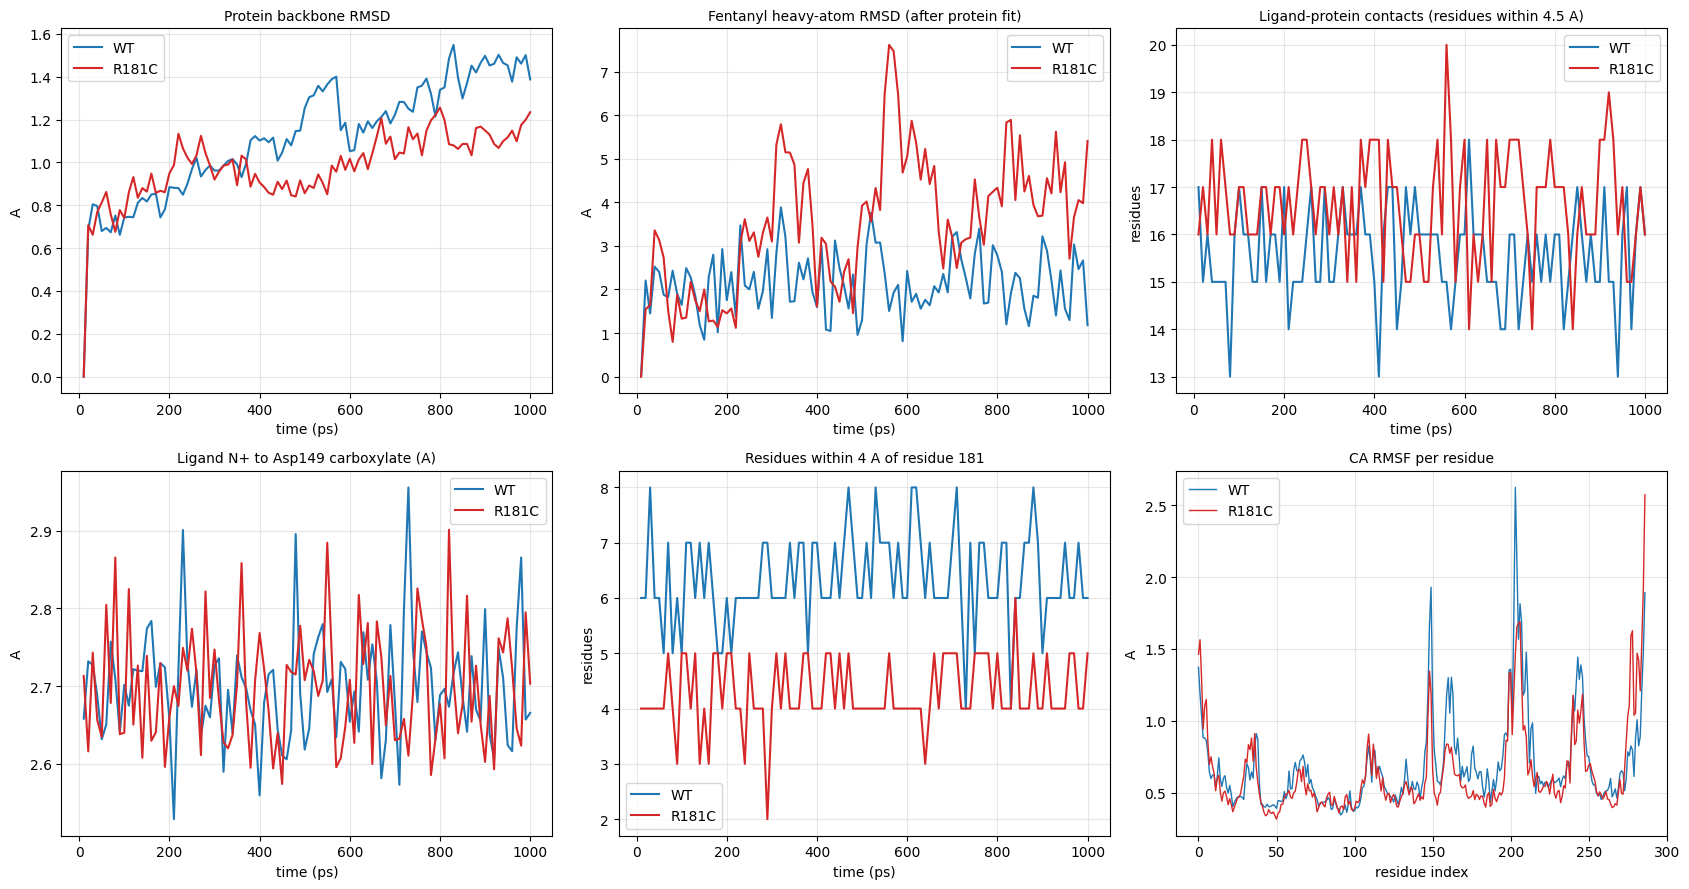


Saved: analysis_wt_vs_r181c.png, wt_analysis.csv, r181c_analysis.csv
Reminder: this is a 1 ns pilot run (single replica). Differences between WT and R181C are NOT statistically meaningful.


In [ ]:
import os, glob
import numpy as np
from google.colab import drive
drive.mount('/content/drive')

os.chdir('/content/drive/MyDrive/Mu_Receptor_Project')
print("Working in:", os.getcwd())

import mdtraj as md
import matplotlib
import matplotlib.pyplot as plt

VARIANTS = ['wt', 'r181c']
COLORS = {'wt': 'tab:blue', 'r181c': 'tab:red'}
FRAME_PS = 10.0          # one frame every 10 ps

# ---------- map file residue numbers (e.g. 181) to topology residue indices ----------
keys = []
for l in open('oriented_receptor_raw.pdb'):
    if l.startswith('ATOM'):
        k = (l[21], l[22:27])
        if not keys or keys[-1] != k:
            keys.append(k)
num2idx = {k[1].strip(): i for i, k in enumerate(keys)}
IDX_181 = num2idx['181']
IDX_149 = num2idx['149']      # conserved Asp (D3.32), key salt-bridge partner of the ligand N+

def analyse(prefix):
    dcds = sorted(glob.glob(f'{prefix}_prod_[0-9][0-9].dcd'))
    print(f"\n=========== {prefix.upper()} | {len(dcds)} DCD files ===========")
    traj = md.load(dcds, top=f'{prefix}_system_solvated.pdb')
    top = traj.topology
    n = traj.n_frames
    t = (np.arange(n) + 1) * FRAME_PS
    print("Frames:", n, "| simulated time (ps):", t[-1])

    res181, res149 = top.residue(IDX_181), top.residue(IDX_149)
    print("Residue 181 in this system:", res181.name, "| residue 149:", res149.name)

    prot = top.select('protein')
    bb = top.select('protein and backbone')
    ca = top.select('protein and name CA')
    prot_heavy = top.select('protein and not element H')
    lig = top.select('not protein and not water and not (resname POP or resname NA or resname CL)')
    lig_heavy = np.array([i for i in lig if top.atom(i).element.symbol != 'H'])
    print("Ligand atoms:", len(lig), "| heavy atoms:", len(lig_heavy), "(expected 25)")
    assert len(lig_heavy) == 25, "Ligand selection is wrong"

    # protein backbone RMSD (fit on backbone)
    prot_rmsd = md.rmsd(traj, traj, 0, atom_indices=bb) * 10

    # superpose on backbone, then ligand RMSD without refitting (shows ligand movement in the pocket)
    # NOTE: superpose rotates coordinates but NOT the periodic box, so it is done on a COPY.
    # All distance/contact calculations below use the original, unrotated traj.
    fit = traj[:]
    fit.superpose(traj, frame=0, atom_indices=bb)
    d = fit.xyz[:, lig_heavy, :] - fit.xyz[0, lig_heavy, :]
    lig_rmsd = np.sqrt((d ** 2).sum(2).mean(1)) * 10

    # per-residue fluctuation (CA RMSF)
    rmsf = md.rmsf(fit, None, atom_indices=ca) * 10

    # ligand-protein contacts (heavy atoms within 4.5 A)
    nb = md.compute_neighbors(traj, 0.45, lig_heavy, haystack_indices=prot_heavy)
    contact_res = [set(top.atom(a).residue.index for a in fr) for fr in nb]
    n_contacts = np.array([len(s) for s in contact_res])
    occ = {}
    for s in contact_res:
        for r in s:
            occ[r] = occ.get(r, 0) + 1
    occ = {r: c / n for r, c in occ.items()}

    # salt bridge: ligand N atoms to Asp149 carboxylate oxygens
    lig_N = [i for i in lig_heavy if top.atom(i).element.symbol == 'N']
    asp_O = [a.index for a in res149.atoms if a.name in ('OD1', 'OD2')]
    sb = {}
    for ni in lig_N:
        pairs = [(ni, o) for o in asp_O]
        sb[ni] = md.compute_distances(traj, pairs).min(axis=1) * 10

    # environment of residue 181 (other protein residues within 4 A of its heavy atoms)
    a181 = [a.index for a in res181.atoms if a.element.symbol != 'H']
    hay = [i for i in prot_heavy if abs(top.atom(i).residue.index - IDX_181) > 1]
    nb181 = md.compute_neighbors(traj, 0.40, a181, haystack_indices=hay)
    env = [set(top.atom(a).residue.index for a in fr) for fr in nb181]
    n_env = np.array([len(s) for s in env])
    occ181 = {}
    for s in env:
        for r in s:
            occ181[r] = occ181.get(r, 0) + 1
    occ181 = {r: c / n for r, c in occ181.items()}

    # minimum distance ligand to residue 181
    pairs = [(a, b) for a in lig_heavy for b in a181]
    d181 = md.compute_distances(traj, pairs).reshape(n, len(lig_heavy), len(a181)).min(axis=(1, 2)) * 10

    # ---------- printed summary ----------
    print(f"Protein backbone RMSD (A): mean {prot_rmsd.mean():.2f} +/- {prot_rmsd.std():.2f} | final {prot_rmsd[-1]:.2f}")
    print(f"Ligand heavy-atom RMSD (A): mean {lig_rmsd.mean():.2f} +/- {lig_rmsd.std():.2f} | final {lig_rmsd[-1]:.2f}")
    print(f"Ligand-protein contacts (residues within 4.5 A): mean {n_contacts.mean():.1f}")
    for ni, dist in sb.items():
        print(f"Ligand N ({top.atom(ni).name}) to Asp149 O: mean {dist.mean():.2f} A | min {dist.min():.2f} A")
    print(f"Min distance ligand to residue 181: mean {d181.mean():.1f} A")
    print(f"Residues within 4 A of residue 181: mean {n_env.mean():.1f}")

    top_pocket = sorted(occ.items(), key=lambda x: -x[1])[:10]
    print("Top ligand-contact residues (name, file number, occupancy):")
    for r, o in top_pocket:
        print(f"   {top.residue(r).name}{keys[r][1].strip()}  {o:.2f}")
    top_env = sorted(occ181.items(), key=lambda x: -x[1])[:8]
    print("Residues most often near residue 181:")
    for r, o in top_env:
        print(f"   {top.residue(r).name}{keys[r][1].strip()}  {o:.2f}")

    # save numeric data
    np.savetxt(f'{prefix}_analysis.csv',
               np.column_stack([t, prot_rmsd, lig_rmsd, n_contacts, n_env, d181]),
               delimiter=',', header='time_ps,protein_rmsd_A,ligand_rmsd_A,ligand_contact_residues,res181_neighbors,ligand_to_res181_A',
               comments='')
    return dict(t=t, prot_rmsd=prot_rmsd, lig_rmsd=lig_rmsd, rmsf=rmsf, n_contacts=n_contacts,
                sb=sb, n_env=n_env, d181=d181, top=top, lig_N=lig_N)

results = {v: analyse(v) for v in VARIANTS}

# ---------- plots ----------
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
for v in VARIANTS:
    r = results[v]
    c = COLORS[v]
    ax[0, 0].plot(r['t'], r['prot_rmsd'], color=c, label=v.upper())
    ax[0, 1].plot(r['t'], r['lig_rmsd'], color=c, label=v.upper())
    ax[0, 2].plot(r['t'], r['n_contacts'], color=c, label=v.upper())
    # salt bridge: use the ligand N that is closest on average to Asp149
    best = min(r['sb'], key=lambda k: r['sb'][k].mean())
    ax[1, 0].plot(r['t'], r['sb'][best], color=c, label=v.upper())
    ax[1, 1].plot(r['t'], r['n_env'], color=c, label=v.upper())
    ax[1, 2].plot(np.arange(len(r['rmsf'])), r['rmsf'], color=c, label=v.upper(), lw=1)

titles = ['Protein backbone RMSD', 'Fentanyl heavy-atom RMSD (after protein fit)',
          'Ligand-protein contacts (residues within 4.5 A)', 'Ligand N+ to Asp149 carboxylate (A)',
          'Residues within 4 A of residue 181', 'CA RMSF per residue']
ylabels = ['A', 'A', 'residues', 'A', 'residues', 'A']
xlabels = ['time (ps)'] * 5 + ['residue index']
for a, ti, yl, xl in zip(ax.ravel(), titles, ylabels, xlabels):
    a.set_title(ti, fontsize=10)
    a.set_ylabel(yl)
    a.set_xlabel(xl)
    a.legend()
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('analysis_wt_vs_r181c.png', dpi=200)
plt.show()

print("\nSaved: analysis_wt_vs_r181c.png, wt_analysis.csv, r181c_analysis.csv")
print("Reminder: this is a 1 ns pilot run (single replica). Differences between WT and R181C are NOT statistically meaningful.")